# SPARC4-like registration: a bright star leaving a distorted field

Generate an **RA, Dec, flux** catalogue, project it onto an ideal detector, add a constant drift, apply a fixed field distortion, and render simple Gaussian stars with `library.gen_image`. Compare full-image and centered-window registration against the **known displacement of a point initially at the optical center**. This is one photometric channel, with no polarimetric splitting.

The instrument anchors are a 1024 × 1024 detector and channel-1 scale of [0.339 arcsec/pixel (LNA/COAST)](https://coast.lna.br/home/sparc4/information-for-users). [Schlindwein et al. (2024), §3.1 and Fig. 1](https://sab-astro.org.br/wp-content/uploads/2024/05/WagnerSchlindwein2.pdf) reports distortion growing toward the edges to about 5 arcsec, modeled with a third-order polynomial. Here a **synthetic radial cubic**, with that amplitude at the ideal-field corners, represents the distortion; it is not the measured per-channel calibration.

We deliberately omit realistic noise, aberrations and detector effects. The study isolates geometry and the loss of a dominant star. Run all cells from the `astropop-studies` directory using a kernel with the local Astropop checkout installed. Runtime requires no network.


In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from matplotlib.patches import Rectangle
from astropy.table import Table
from astropy.wcs import WCS
from astropop.framedata import FrameData
from astropop.image.register import register_framedata_list

%matplotlib inline

rng = np.random.default_rng(20261018)
size = 1024
n_frames = 40
n_sources = 1000                    # ordinary stars; add one bright star
pixel_scale = 0.34                # arcsec/pixel
corner_distortion_arcsec = 5.0     # synthetic cubic amplitude
bright_flux = 1_000_000.0          # arbitrary linear flux units
sigma = 2.0                       # Gaussian width in pixels
# Ideal detector coordinates (x, y), before distortion; endpoints may be outside.
bright_start_xy = np.array([820, 820])
bright_end_xy = np.array([1180, 1180])
field_flux_range = (300.0, 10_000.0)  # log-uniform integrated flux
window_size = 600                  # centered square, in pixels

if n_frames < 2:
    raise ValueError('n_frames must be at least two')
if any(np.shape(p) != (2,) or not np.isfinite(p).all()
       for p in (bright_start_xy, bright_end_xy)):
    raise ValueError('Bright-star positions must contain two finite coordinates')
if not 0 < field_flux_range[0] <= field_flux_range[1] < np.inf:
    raise ValueError('Flux range must be positive, finite and ordered')
if not isinstance(window_size, (int, np.integer)) or not 1 <= window_size <= size:
    raise ValueError('window_size must be an integer between one and size')
margin = (size-window_size)//2
window = (slice(margin, margin+window_size),)*2
center_xy = np.full(2, (size-1)/2)
step_xy = (bright_end_xy-bright_start_xy)/(n_frames-1)
drift_xy = np.linspace(np.zeros(2), bright_end_xy-bright_start_xy, n_frames)


## Sources → drift → distortion → images

The catalogue covers the whole pointing path, with a small border, so ordinary stars enter and leave naturally throughout the drift. The final row is the single very bright star. Its configurable endpoints determine the drift; a trajectory toward a corner reaches the region with the strongest radial distortion. Depending on the starting position, it may already be outside the centered window. The TAN WCS supplies the initial RA/Dec-to-pixel projection; drift is then a constant displacement on that ideal focal plane.

For ideal position **p**, the distortion is **D(p) = p + k (p − c) |p − c|²**, where **c** is the detector center and **k** sets the corner amplitude. Each star appears at **D(p + drift)**. Applying drift before distortion is essential: shifting an already distorted image would impose the same displacement on every star.

All positions and returned shifts are **(x, y) = (column, row)**. The window is in NumPy **(row slice, column slice)** order. Pixel centers are 0…1023 and detector boundaries are −0.5 and 1023.5.

Set `bright_start_xy`, `bright_end_xy`, `field_flux_range`, and `window_size` in the settings cell. Positions are ideal, pre-distortion detector coordinates, not sky coordinates or distorted centroids. The endpoint determines a constant drift for the whole field. Endpoints outside the detector are allowed; crossings are optional. The flux range is sampled logarithmically and the square window is centered on the detector.


In [2]:
# Draw an extended field and turn its ideal positions into an RA/Dec catalogue.
wcs = WCS(naxis=2)
wcs.wcs.crpix = center_xy + 1       # FITS WCS uses one-based reference pixels
wcs.wcs.crval = [280.0, -6.0]       # arbitrary field center, degrees
wcs.wcs.cdelt = [-pixel_scale/3600, pixel_scale/3600]
wcs.wcs.ctype = ['RA---TAN', 'DEC--TAN']

# Cover every sky position that can enter the detector during the drift.
xy = rng.uniform(-150 - drift_xy.max(axis=0),
                 size + 150 - drift_xy.min(axis=0), (n_sources, 2))
xy = np.vstack([xy, bright_start_xy])    # configurable bright-star starting point
ra, dec = wcs.pixel_to_world_values(xy[:, 0], xy[:, 1])
flux = np.r_[10**rng.uniform(np.log10(field_flux_range[0]), np.log10(field_flux_range[1]), n_sources), bright_flux]
sources = Table({'ra': ra, 'dec': dec, 'flux': flux})
sources['ra'].unit = 'deg'
sources['dec'].unit = 'deg'
ideal_xy = np.column_stack(wcs.world_to_pixel_values(sources['ra'], sources['dec']))


def distort(xy):
    q = np.asarray(xy) - center_xy
    k = (corner_distortion_arcsec/pixel_scale) / np.linalg.norm(center_xy)**3
    return np.asarray(xy) + k*q*np.sum(q*q, axis=-1)[..., None]


positions = distort(ideal_xy[None, :, :] + drift_xy[:, None, :])
# Track an ideal sky point initially at the optical center. This is an analytic
# benchmark, independent of the source brightnesses and registration results.
expected_xy = distort(center_xy + drift_xy) - distort(center_xy)
bright_positions = positions[:, -1]
inside_image = np.all((bright_positions >= -0.5) &
                      (bright_positions < size-0.5), axis=1)
def first_exit(inside):
    """First inside-to-outside transition, or None if there is no crossing."""
    crossings = np.flatnonzero(inside[:-1] & ~inside[1:]) + 1
    return int(crossings[0]) if len(crossings) else None


exit_frame = first_exit(inside_image)
window_start = np.array([window[1].start, window[0].start])
window_stop = np.array([window[1].stop, window[0].stop])
inside_window = np.all((bright_positions >= window_start-0.5) &
                       (bright_positions < window_stop-0.5), axis=1)
window_exit_frame = first_exit(inside_window)
print(f'{len(sources)} sources; drift per frame: {step_xy} pixels.')
print(f'First window exit: {window_exit_frame}; image exit: {exit_frame} '
      '(zero based; None means no exit).')
sources[-5:]

1001 sources; drift per frame: [9.23076923 9.23076923] pixels.
First window exit: None; image exit: 21 (zero based; None means no exit).


ra,dec,flux
deg,deg,
float64,float64,float64
279.9901170203294,-6.0278721588373045,3528.126623441948
280.0952780051826,-5.997520589540259,3181.94242801899
279.9963990900359,-5.95230592136337,7206.976280268692
280.00458211479867,-5.987700501024433,451.3773907467848
279.9707049673491,-5.97086311657999,1000000.0


In [3]:
# Bound each Gaussian to eight sigma instead of evaluating it across 1024² pixels.
# Preallocate the sequence to avoid holding both a list and a stacked copy.
from time import perf_counter
from importlib import import_module, reload

# Jupyter keeps imports cached across cell runs. In particular, the old renderer
# accepted **kwargs and silently ignored truncate, falling back to full frames.
# Reload here (not just in the setup cell) so iterative runs use the saved code.
image_generation = reload(import_module('library.gen_image'))
print(f'Renderer: {image_generation.__file__}', flush=True)
started = perf_counter()
images = np.empty((n_frames, size, size), dtype=np.float32)
flux = np.asarray(sources['flux'])
for i, xy in enumerate(positions):
    visible = np.all((xy > -8*sigma) & (xy < size+8*sigma), axis=1)
    images[i] = image_generation.gen_image((size, size), xy[visible, 0], xy[visible, 1],
                          flux[visible], sky=100, rdnoise=0, model='gaussian',
                          sigma=sigma, theta=0, truncate=8, skip_poisson=True)
    if (i+1) % 10 == 0 or i+1 == n_frames:
        print(f'Rendered {i+1}/{n_frames} frames in {perf_counter()-started:.2f} s',
              flush=True)
print(f'Image sequence: {images.shape}; generated in {perf_counter()-started:.3f} s')


Renderer: /home/julio/Code/astropop-studies/library/gen_image.py
Rendered 10/40 frames in 0.46 s
Rendered 20/40 frames in 0.96 s
Rendered 30/40 frames in 1.49 s
Rendered 40/40 frames in 1.98 s
Image sequence: (40, 1024, 1024); generated in 1.983 s


## Compare with the expected central shift

Both methods use the same images and the same **first-frame reference**. Only `window` differs. Astropop's `CrossCorrelationRegister` uses unnormalized correlation (`normalization=None`), so a very bright star can dominate the estimate. `register_framedata_list` estimates the shifts and resamples the full images. We read the forward **[dx, dy]** displacements from the returned frames’ `astropop registration_shift_x/y` metadata. Only these shifts are retained for the comparison; input images remain unchanged.

The exact center displacement is not a universal translation for the whole distorted field. It is the benchmark appropriate to this central-region comparison. The bright-star starting position is independently configurable; its true displacement generally differs from this central benchmark. While it is inside the window, it can dominate both estimates. Its crossings of the window and detector boundaries are marked separately.

Partial clipping and disappearance can spoil correlation without distortion. The default center-to-corner motion also exceeds half the window width, and eventually half the full-image width: first-frame overlap decreases and the FFT correlation peak can wrap to another displacement. Thus this scenario is not a clean test of distortion alone or a guarantee that the fixed centered window performs better.
The expected shift always follows the point initially at the optical center, independently of the configurable bright-star position. Large endpoint displacements can also cause overlap loss and FFT correlation wrapping.


In [4]:
def registration_shifts(ref_image):
    # Keep the simulated images unchanged: each method registers separate copies.
    frame_list = [FrameData(image, dtype=np.float32) for image in images]
    results = {}
    for name, region in [('Full image', None), ('Centered window', window)]:
        registered = register_framedata_list(
            frame_list, algorithm='cross-correlation', ref_image=ref_image,
            window=region, upsample_factor=20, clip_output=False,
            inplace=False, skip_failure=False)
        # Metadata contains forward (x, y) displacement from reference to moving.
        results[name] = np.array([
            [frame.meta['astropop registration_shift_x'],
             frame.meta['astropop registration_shift_y']]
            for frame in registered
        ])
        assert np.isfinite(results[name]).all(), name
        np.testing.assert_allclose(results[name][ref_image], [0, 0], atol=1e-10)
        # Only the shifts are needed here; release resampled images before the
        # next method, rather than retaining several full registered sequences.
        del registered
    return results


shifts = registration_shifts(ref_image=0)


2026-10-19 10:02:08,835 astropop - INFO - Registering image 1 from 40  [register]
2026-10-19 10:02:08,846 astropop - INFO - Images are equal, skipping registering.  [register]
2026-10-19 10:02:09,114 astropop - INFO - Registering image 2 from 40  [register]
2026-10-19 10:02:09,338 astropop - INFO - Filling registered image with cval=100.00  [register]
2026-10-19 10:02:09,338 astropop - INFO - Registering image with: translation=[9.44999981 9.44999981], rotation=0.00°  [register]
2026-10-19 10:02:09,687 astropop - INFO - Registering image 3 from 40  [register]
2026-10-19 10:02:09,897 astropop - INFO - Filling registered image with cval=100.00  [register]
2026-10-19 10:02:09,898 astropop - INFO - Registering image with: translation=[18.89999962 18.89999962], rotation=0.00°  [register]
2026-10-19 10:02:10,213 astropop - INFO - Registering image 4 from 40  [register]
2026-10-19 10:02:10,414 astropop - INFO - Filling registered image with cval=100.00  [register]
2026-10-19 10:02:10,414 astr

In [5]:
# A self-contained animation with play/pause, frame slider and speed controls.
# Embedded JavaScript frames need neither a live widget backend nor an encoder.
fig, ax = plt.subplots(figsize=(6, 6), layout='constrained')
image_artist = ax.imshow(images[0], origin='lower', cmap='gray', vmin=0, vmax=300)
ax.add_patch(Rectangle((margin-0.5, margin-0.5), window_size, window_size,
                       fill=False, ec='cyan', lw=1.5, label='Registration window'))
bright_marker, = ax.plot([], [], 'o', ms=12, mfc='none', mec='red', label='Bright star')
frame_title = ax.set_title('')
ax.set(xlim=(-0.5, size-0.5), ylim=(-0.5, size-0.5),
       xlabel='x (pixels)', ylabel='y (pixels)')
ax.legend(loc='upper left', fontsize=8)


def animate_frame(i):
    image_artist.set_data(images[i])
    bright_marker.set_data([bright_positions[i, 0]], [bright_positions[i, 1]])
    if not inside_image[i]:
        location = 'outside image'
    elif not inside_window[i]:
        location = 'outside centered window'
    else:
        location = 'inside centered window'
    frame_title.set_text(f'Frame {i}/{n_frames-1}: bright star {location}')
    return image_artist, bright_marker, frame_title


movie = FuncAnimation(fig, animate_frame, frames=n_frames, interval=200,
                      repeat=False, blit=False)
movie_html = movie.to_jshtml(default_mode='once')
# Use text controls instead of icons from an external font stylesheet.
movie_html = re.sub(r'<link\b[^>]*>', '', movie_html)
movie_html = ('<style>.animation .fa{display:none}'
              '.animation button::after{content:attr(aria-label)}'
              '.animation .anim-buttons button{width:auto;padding:4px 6px}'
              '.animation .anim-buttons{max-width:600px;display:flex;flex-wrap:wrap;'
              'justify-content:center;gap:2px}</style>' + movie_html)
plt.close(fig)                    # suppress the extra static inline figure
# Press Play to follow the full sequence; pause or scrub to inspect a crossing.
display(HTML(movie_html))


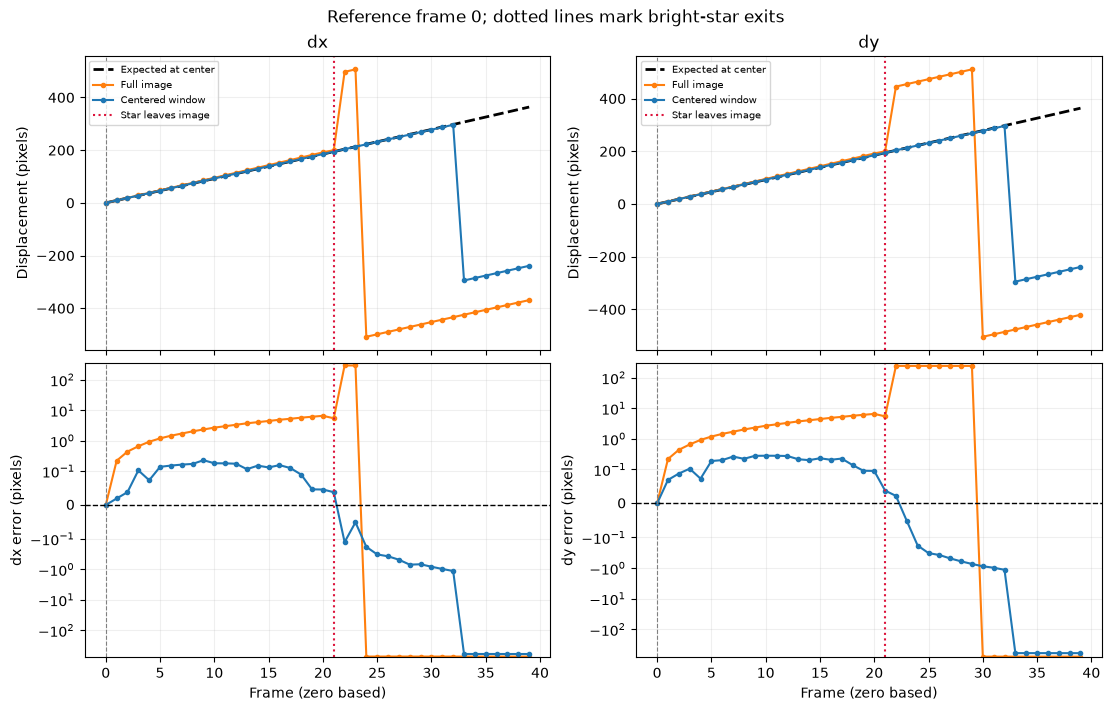

Vector errors relative to the expected center displacement (excluding reference):
Full image        RMSE = 626.917 px; maximum = 1072.979 px
Centered window   RMSE = 360.600 px; maximum = 852.064 px


In [6]:
def plot_shift_comparison(shifts, expected_xy, ref_image):
    # One comparison figure: actual shifts above, error against the center below.
    frames = np.arange(n_frames)
    colors = {'Full image': 'tab:orange', 'Centered window': 'tab:blue'}
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, layout='constrained')
    for dim, label in enumerate(('dx', 'dy')):
        axes[0, dim].plot(frames, expected_xy[:, dim], 'k--', lw=2, label='Expected at center')
        for name, values in shifts.items():
            axes[0, dim].plot(frames, values[:, dim], '.-', color=colors[name], label=name)
            axes[1, dim].plot(frames, values[:, dim]-expected_xy[:, dim], '.-',
                              color=colors[name], label=name)
        axes[0, dim].set(title=label, ylabel='Displacement (pixels)')
        axes[1, dim].axhline(0, color='k', ls='--', lw=1)
        axes[1, dim].set_yscale('symlog', linthresh=0.1)
        axes[1, dim].set(ylabel=f'{label} error (pixels)', xlabel='Frame (zero based)')
        for ax in axes[:, dim]:
            if window_exit_frame is not None:
                ax.axvline(window_exit_frame, color='teal', ls=':', label='Star leaves window')
            if exit_frame is not None:
                ax.axvline(exit_frame, color='crimson', ls=':', label='Star leaves image')
            ax.axvline(ref_image, color='0.5', ls='--', lw=0.8)
            ax.grid(alpha=0.2)
        axes[0, dim].legend(fontsize=7)
    fig.suptitle(f'Reference frame {ref_image}; dotted lines mark bright-star exits')
    plt.show()

    print('Vector errors relative to the expected center displacement (excluding reference):')
    for name, values in shifts.items():
        non_reference = frames != ref_image
        error = np.linalg.norm(values[non_reference]-expected_xy[non_reference], axis=1)
        print(f'{name:16s}  RMSE = {np.sqrt(np.mean(error**2)):.3f} px; '
              f'maximum = {error.max():.3f} px')


plot_shift_comparison(shifts, expected_xy, ref_image=0)


Read the pre-exit error trend separately from the jump when the bright star disappears. The bottom panels use a **symmetric-log scale**, linear within ±0.1 pixels, so small biases and large outliers remain visible together. No measured shifts are clipped or rejected.

For two simple checks, rerun with `corner_distortion_arcsec = 0` to remove differential distortion, or set `bright_flux = 5000` to remove the star's dominance. Whether the bright star crosses the fixed centered window depends on the chosen endpoints. For an uncontaminated-window comparison, move the star outside the window initially and use a smaller total drift. A window estimates a translation for its region; it does not correct optical distortion, loss of overlap, or correlation wrapping across the detector.


## Use the middle image as the reference

Repeat both registrations with `ref_image = n_frames // 2` (the later central frame for an even-length sequence). The input images, fixed detector window and correlation settings are unchanged. `register_framedata_list` estimates every shift directly against this reference; these are **new registrations**, not the first-frame shifts with an offset subtracted.

The analytic benchmark now follows the sky point located at the optical center **in the middle frame**. Apply `drift_xy - drift_xy[ref_image]` before distortion to calculate its expected displacement. This keeps the benchmark appropriate to the centered region for each reference choice. Negative shifts before the reference are expected. A middle reference can reduce the largest displacement and improve overlap, but cannot remove differential distortion or guarantee a correct correlation peak. The bright star may also be absent from the reference.


2026-10-19 10:03:05,805 astropop - INFO - Registering image 1 from 40  [register]
2026-10-19 10:03:06,028 astropop - INFO - Filling registered image with cval=100.00  [register]
2026-10-19 10:03:06,030 astropop - INFO - Registering image with: translation=[-191.6499939 -191.6499939], rotation=0.00°  [register]
2026-10-19 10:03:06,374 astropop - INFO - Registering image 2 from 40  [register]
2026-10-19 10:03:06,551 astropop - INFO - Filling registered image with cval=100.00  [register]
2026-10-19 10:03:06,552 astropop - INFO - Registering image with: translation=[-182.19999695 -182.19999695], rotation=0.00°  [register]
2026-10-19 10:03:06,864 astropop - INFO - Registering image 3 from 40  [register]
2026-10-19 10:03:07,097 astropop - INFO - Filling registered image with cval=100.00  [register]
2026-10-19 10:03:07,098 astropop - INFO - Registering image with: translation=[-172.75 -172.75], rotation=0.00°  [register]
2026-10-19 10:03:07,477 astropop - INFO - Registering image 4 from 40  [

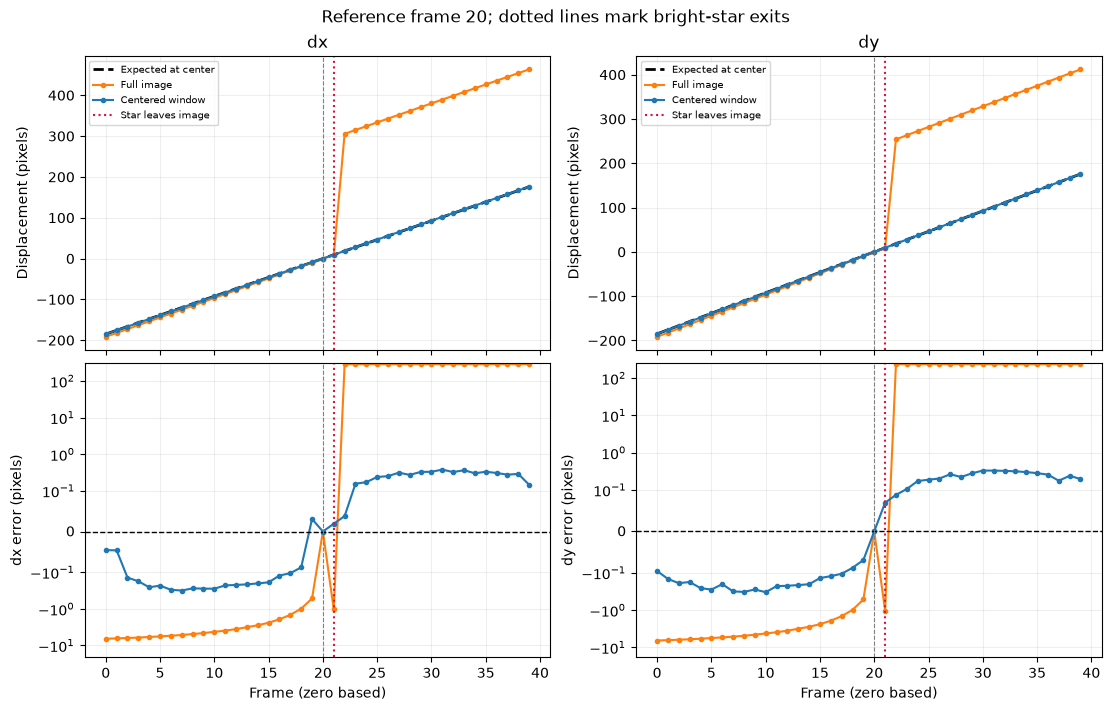

Vector errors relative to the expected center displacement (excluding reference):
Full image        RMSE = 252.806 px; maximum = 372.363 px
Centered window   RMSE = 0.333 px; maximum = 0.504 px


In [7]:
middle_ref_image = n_frames // 2
middle_shifts = registration_shifts(ref_image=middle_ref_image)
relative_drift_xy = drift_xy-drift_xy[middle_ref_image]
middle_expected_xy = distort(center_xy+relative_drift_xy)-distort(center_xy)
plot_shift_comparison(middle_shifts, middle_expected_xy, ref_image=middle_ref_image)
